# Ex0 - Check your PyTorch installation

Run all cells before starting `ex1.ipynb`.

## 1. Python and packages

In [1]:
import sys
import importlib.metadata as metadata

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)

for package in ["torch", "torchvision", "numpy", "matplotlib", "tqdm"]:
    print(f"{package}: {metadata.version(package)}")

# These are useful for local notebooks, but may be absent on Google Colab.
for package in ["ipykernel", "jupyterlab"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not installed (optional on Colab)")

Python: 3.12.15
Python executable: c:\Users\tomas\.conda\envs\pytorch\python.exe
torch: 2.14.1
torchvision: 0.29.1
numpy: 2.5.4
matplotlib: 3.11.2
tqdm: 4.70.1
ipykernel: 7.4.0
jupyterlab: 4.6.4


c:\Users\tomas\.conda\envs\pytorch\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


If you see `ModuleNotFoundError`, activate the correct Conda environment and install the missing package. In VS Code, also check the notebook kernel (top right).

## 2. CPU or GPU?

In [2]:
cuda_available = torch.cuda.is_available()
mps_available = hasattr(torch.backends, "mps") and torch.backends.mps.is_available()

if cuda_available:
    device = torch.device("cuda")
    print("NVIDIA GPU:", torch.cuda.get_device_name(0))
elif mps_available:
    device = torch.device("mps")
    print("Apple Silicon GPU (MPS) available")
else:
    device = torch.device("cpu")
    print("Using CPU (this is fine!)")

print("Selected device:", device)

Using CPU (this is fine!)
Selected device: cpu


## 3. Tensors and automatic differentiation

In [3]:
x = torch.tensor([1.0, 2.0, 3.0], device=device, requires_grad=True)
y = (x ** 2).sum()
y.backward()

assert torch.allclose(x.grad, torch.tensor([2.0, 4.0, 6.0], device=device))
print("Tensor operations: OK")
print("Autograd: OK")

Tensor operations: OK
Autograd: OK


## 4. Train a small neural network

In [4]:
torch.manual_seed(42)

# Learn y = 3x + 1
x_train = torch.linspace(-1, 1, 64, device=device).unsqueeze(1)
y_train = 3 * x_train + 1

model = torch.nn.Linear(1, 1).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.2)
loss_fn = torch.nn.MSELoss()

losses = []
for _ in tqdm(range(80), desc="Training"):
    optimizer.zero_grad()
    loss = loss_fn(model(x_train), y_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

assert np.all(np.isfinite(losses)), "Training produced a non-finite loss"
assert losses[-1] < losses[0] * 0.1, "Loss did not decrease enough"

print(f"First loss: {losses[0]:.4f}")
print(f"Last loss:  {losses[-1]:.4f}")
print("Training: OK")

Training: 100%|██████████| 80/80 [00:00<00:00, 7981.74it/s]

First loss: 1.7475
Last loss:  0.0000
Training: OK


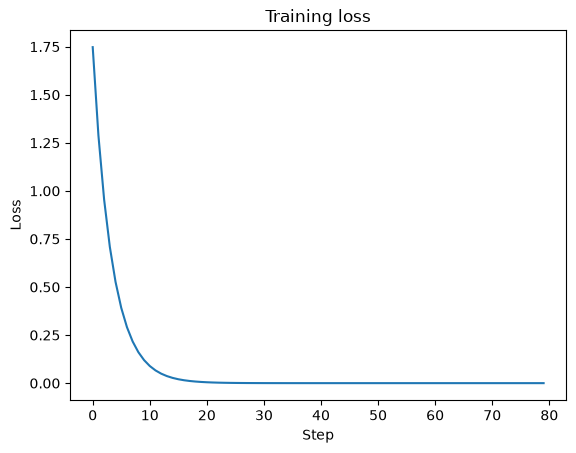

In [5]:
plt.plot(losses)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training loss")
plt.show()

## 5. Data loading and images

DataLoader: OK


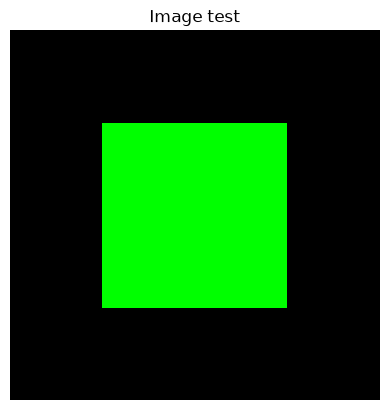

torchvision and matplotlib: OK


In [6]:
from torch.utils.data import TensorDataset, DataLoader
from torchvision.transforms import ToTensor

# DataLoader works on CPU; batches can then be moved to the chosen device.
dataset = TensorDataset(x_train.cpu(), y_train.cpu())
loader = DataLoader(dataset, batch_size=8, shuffle=True)
inputs, targets = next(iter(loader))
assert inputs.shape == (8, 1) and targets.shape == (8, 1)
print("DataLoader: OK")

# Simple image, no dataset download required.
image = np.zeros((16, 16, 3), dtype=np.uint8)
image[4:12, 4:12, 1] = 255
image_tensor = ToTensor()(image)
assert image_tensor.shape == (3, 16, 16)

plt.imshow(image)
plt.axis("off")
plt.title("Image test")
plt.show()
print("torchvision and matplotlib: OK")

## Done!

In [7]:
print("All tests passed! You can move on to ex1.ipynb :) ")

All tests passed! You can move on to ex1.ipynb :) 
